Load & Prepare the Dataset

In [5]:
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split

# Load the dataset
data_dir = Path("../data")
csv_files = list(data_dir.glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, found {len(csv_files)}"
    )

df = pd.read_csv(csv_files[0])

# Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", float("nan"), regex=True),
    errors="coerce"
)

# Separate features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Use the same split settings as the baseline
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)
Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


Build the Pipeline with Random Forest

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

# Identify numeric and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Preprocess numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Numeric features: 4
Categorical features: 15
Random Forest model trained successfully!


Evaluate the Model

In [7]:
# Generate predictions
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_proba_rf)

print("Random Forest Evaluation")
print("-" * 30)
print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Evaluation
------------------------------
Accuracy:  0.7637
Precision: 0.5482
Recall:    0.6230
F1-score:  0.5832
ROC-AUC:   0.8230

Confusion Matrix:
[[843 192]
 [141 233]]


### Experiment 1: Logistic Regression vs. Random Forest

Both models were evaluated on the same stratified test split of 1,409 customers.

Logistic Regression achieved 80.55% accuracy, 65.72% precision, 55.88% recall, an F1-score of 0.6040, and ROC-AUC of 0.8419.

Random Forest achieved 76.37% accuracy, 54.82% precision, 62.30% recall, an F1-score of 0.5832, and ROC-AUC of 0.8230.

Random Forest identified more actual churners at the default classification threshold but generated more false positives. Logistic Regression performed better on accuracy, precision, F1-score, and ROC-AUC.

**Conclusion:** Logistic Regression remains the stronger overall baseline on these metrics, while Random Forest offers higher recall at the default threshold. Further validation is needed before selecting a final model.

In [8]:
from pathlib import Path
import pandas as pd

report_dir = Path("../reports")
report_dir.mkdir(parents=True, exist_ok=True)

comparison_df = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "accuracy": 0.8055,
        "precision": 0.6572,
        "recall": 0.5588,
        "f1_score": 0.6040,
        "roc_auc": 0.8419,
    },
    {
        "model": "Random Forest",
        "accuracy": rf_accuracy,
        "precision": rf_precision,
        "recall": rf_recall,
        "f1_score": rf_f1,
        "roc_auc": rf_roc_auc,
    },
])

comparison_df.to_csv(
    report_dir / "model_comparison.csv",
    index=False
)

print(comparison_df.round(4))
print("\nModel comparison saved successfully.")

                 model  accuracy  precision  recall  f1_score  roc_auc
0  Logistic Regression    0.8055     0.6572  0.5588    0.6040   0.8419
1        Random Forest    0.7637     0.5482  0.6230    0.5832   0.8230

Model comparison saved successfully.


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numeric preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
lr_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build Logistic Regression pipeline
lr_model = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression retrained successfully!")

Logistic Regression retrained successfully!


Inspect the Coffiients

In [13]:
import pandas as pd

lr_classifier = lr_model.named_steps["classifier"]
lr_preprocessor = lr_model.named_steps["preprocessor"]

feature_names = lr_preprocessor.get_feature_names_out()
coefficients = lr_classifier.coef_[0]

importance_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

importance_df["absolute_coefficient"] = (
    importance_df["coefficient"].abs()
)

importance_df = importance_df.sort_values(
    "absolute_coefficient",
    ascending=False
)

importance_df.head(15)

,feature,coefficient,absolute_coefficient
1,num__tenure,-1.241319,1.241319
38,cat__Contract_Two year,-0.772261,0.772261
15,cat__InternetService_DSL,-0.652406,0.652406
16,cat__InternetService_Fiber optic,0.640026,0.640026
2,num__MonthlyCharges,-0.596392,0.596392
36,cat__Contract_Month-to-month,0.579304,0.579304
3,num__TotalCharges,0.516708,0.516708
39,cat__PaperlessBilling_No,-0.343260,0.343260
25,cat__DeviceProtection_No internet service,-0.301082,0.301082
17,cat__InternetService_No,-0.301082,0.301082


Top Churn Related Coefficients

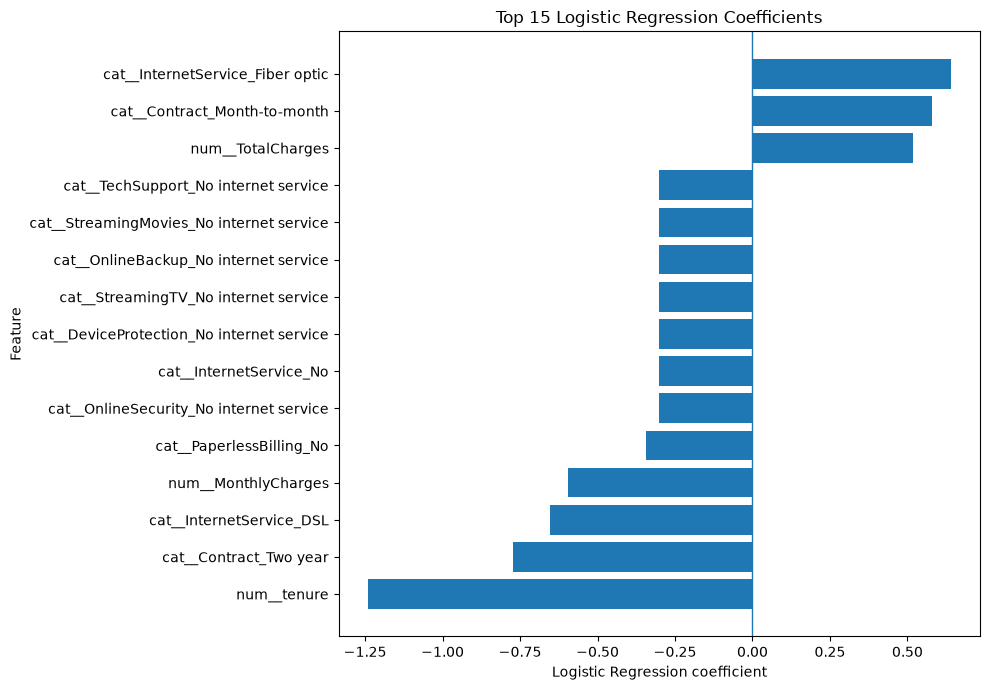

In [14]:
import matplotlib.pyplot as plt

# Select the 15 features with largest absolute coefficients
top_features = importance_df.head(15).sort_values(
    "coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Logistic Regression Coefficients")
plt.tight_layout()
plt.show()